# Circuit A (Also circuit C - note that circuit C is just 3 circuits A)



## Circuit draw
Circuit A is just the DME circuit, with an RZ gate added

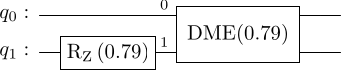

In [1]:
from qiskit import QuantumCircuit
from qiskit.circuit import Gate

# Create a quantum circuit with two qubits
qc = QuantumCircuit(2)

# Define a custom 2-qubit gate called 'DME'
dme_gate = Gate(name=r'DME({0.79})', num_qubits=2, params=[])
phi_z = 0.79

# Apply the gates as per the given description
qc.rz(phi=phi_z,qubit=1)
qc.append(dme_gate, [0, 1])  # DME gate on q_0 and q_1
# qc.append(dme_gate, [0, 2])  # DME gate on q_0 and q_2
# qc.append(dme_gate, [0, 3])  # DME gate on q_0 and q_3
# qc.rz(phi=-phi_z,qubit=1)

# Draw the circuit
qc.draw(output='latex', style="bw")


In [2]:
latex_code = qc.draw(output='latex_source', style="bw")
print(latex_code)

\documentclass[border=2px]{standalone}

\usepackage[braket, qm]{qcircuit}
\usepackage{graphicx}

\begin{document}
\scalebox{1.0}{
\Qcircuit @C=1.0em @R=0.2em @!R { \\
	 	\nghost{{q}_{0} :  } & \lstick{{q}_{0} :  } & \qw & \multigate{1}{\mathrm{DME({0.79})}}_<<<{0} & \qw & \qw\\
	 	\nghost{{q}_{1} :  } & \lstick{{q}_{1} :  } & \gate{\mathrm{R_Z}\,(\mathrm{0.79})} & \ghost{\mathrm{DME({0.79})}}_<<<{1} & \qw & \qw\\
\\ }}
\end{document}


Circuit C is 3 Circuit A stacked

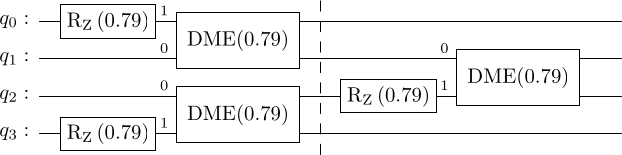

In [3]:
from qiskit import QuantumCircuit
from qiskit.circuit import Gate

# Create a quantum circuit with two qubits
qc = QuantumCircuit(4)

# Define a custom 2-qubit gate called 'DME'
dme_gate = Gate(name=r'DME({0.79})', num_qubits=2, params=[])
phi_z = 0.79

# Apply the gates as per the given description
qc.rz(phi=phi_z,qubit=0)
qc.append(dme_gate, [1, 0])  # DME gate on q_0 and q_1
# qc.rz(phi=-phi_z,qubit=1)

# Apply the gates as per the given description
qc.rz(phi=phi_z,qubit=3)
qc.append(dme_gate, [2, 3])  # DME gate on q_2 and q_3
# qc.rz(phi=-phi_z,qubit=2)
qc.barrier()


dme_gate = Gate(name=r'DME({0.79})', num_qubits=2, params=[])
qc.rz(phi=phi_z,qubit=2)
qc.append(dme_gate, [1, 2])  # DME gate on q_0 and q_1
# qc.rz(phi=-phi_z,qubit=1)


# Draw the circuit
qc.draw(output='latex', style="bw")

In [4]:
latex_code = qc.draw(output='latex_source', style="bw")
print(latex_code)

\documentclass[border=2px]{standalone}

\usepackage[braket, qm]{qcircuit}
\usepackage{graphicx}

\begin{document}
\scalebox{1.0}{
\Qcircuit @C=1.0em @R=0.2em @!R { \\
	 	\nghost{{q}_{0} :  } & \lstick{{q}_{0} :  } & \gate{\mathrm{R_Z}\,(\mathrm{0.79})} & \multigate{1}{\mathrm{DME({0.79})}}_<<<{1} \barrier[0em]{3} & \qw & \qw & \qw & \qw & \qw\\
	 	\nghost{{q}_{1} :  } & \lstick{{q}_{1} :  } & \qw & \ghost{\mathrm{DME({0.79})}}_<<<{0} & \qw & \qw & \multigate{1}{\mathrm{DME({0.79})}}_<<<{0} & \qw & \qw\\
	 	\nghost{{q}_{2} :  } & \lstick{{q}_{2} :  } & \qw & \multigate{1}{\mathrm{DME({0.79})}}_<<<{0} & \qw & \gate{\mathrm{R_Z}\,(\mathrm{0.79})} & \ghost{\mathrm{DME({0.79})}}_<<<{1} & \qw & \qw\\
	 	\nghost{{q}_{3} :  } & \lstick{{q}_{3} :  } & \gate{\mathrm{R_Z}\,(\mathrm{0.79})} & \ghost{\mathrm{DME({0.79})}}_<<<{1} & \qw & \qw & \qw & \qw & \qw\\
\\ }}
\end{document}


## Checking that our circuit perform similarly to the GCI (db-qite iteration) class

Here I have the code snipet that perform the db-qite iteration

In [5]:
from qibo import Circuit
import numpy as np

def execute_gci(gci_step, state_of_recursion, times_dbr):
    """
    Minimal GCI loop returning only energies, intermediate states, final state, and fidelities.

    Args:
        gci_step (callable): Function that performs a GCI step.
        state_of_recursion: Initial quantum state (vector or Circuit).
        nmb_steps (int or None): Number of GCI steps to run.
        times_dbr (list): List of step sizes to try at each iteration.

    Returns:
        Tuple: (energies, states, final_state, fidelities)
    """
    H = np.array([[-1.-0.j, 0], [0, 1.-0.j]])
    state_0 = np.array([1, 0], dtype=complex)

    def fidelity_with_0(state):
        shape = np.shape(state)
        if shape[0] == shape[1]:
            return np.real(np.conj(state_0).T @ state @ state_0)
        else:
            dm = state @ state.T.conj()
            return np.real(np.conj(state_0).T @ dm @ state_0)

    def compute_energy(psi):
        shape = np.shape(psi)
        if shape[0] == shape[1]:
            return np.real(np.trace(psi @ H))
        else:
            return np.real((psi.conj().T @ H @ psi)[0, 0])

    energies = [compute_energy(state_of_recursion)]
    fidelities = [fidelity_with_0(state_of_recursion)]
    states = [state_of_recursion]

    for s in times_dbr:
        state_of_recursion = gci_step(state_of_recursion, s)
        energies.append(compute_energy(state_of_recursion))
        fidelities.append(fidelity_with_0(state_of_recursion))
        states.append(state_of_recursion)

    return energies, states, state_of_recursion, fidelities


And here is the dme that is compiled using heisenberg (ZZ,XX,YY) interaction

In [6]:
import sys
sys.path.append('..')

# Custom functions
from functions.qite_gci import *
from functions.qite_dme import *
from functions.dme import *
from functions.plot_bloch_sphere import *
from functions.plot_process_matrix import plot_process_matrix

# Standard libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

# QuTiP
from qutip import (
    gates, spre, spost, qeye, sigmax, sigmay, sigmaz,
    tensor, Qobj
)
from qutip.tomography import qpt

Z = np.array([[1, 0], [0, -1]])
def RZ(phi):
    return expm(1j*phi*Z)

I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
S = np.array([[1, 0], [0, 1j]])
S_dagger = S.conj().T

II = np.kron(I, I)
XX = np.kron(X, X)
YY = np.kron(Y, Y)
ZZ = np.kron(Z, Z)

def dme_heisenberg(phi):
    ZZ_phi = expm(-1j*phi/2*ZZ)
    YY_phi = np.kron(S_dagger,I) @ np.kron(H,I) @ np.kron(I,S_dagger) @ np.kron(I,H) @ expm(-1j*phi/2*ZZ) @ np.kron(H,I) @ np.kron(S,I) @ np.kron(I,H) @ np.kron(I,S)
    XX_phi = np.kron(H,I) @ np.kron(I,H) @ expm(-1j*phi/2*ZZ) @ np.kron(H,I) @ np.kron(I,H)
    return (ZZ_phi @ YY_phi @ XX_phi)


[Qibo 0.2.12|ERROR|2025-06-12 17:20:14]: The 'qibojit' backends' provider is not available. Check that a Python package named 'qibojit' is installed, and it is exposing valid Qibo backends.
[Qibo 0.2.12|ERROR|2025-06-12 17:20:14]: The 'qibojit' backends' provider is not available. Check that a Python package named 'qibojit' is installed, and it is exposing valid Qibo backends.
[Qibo 0.2.12|INFO|2025-06-12 17:20:14]: Using numpy backend on /CPU:0


I use a random initial state $\ket{\psi_0}$

In [7]:
psi0 = expm(-1j * np.pi/2 * X * 0.4) @ np.array([[0], [1]])
data0 = psi0@psi0.T.conj()

The state after circuit A, as per db-qite iteration is:

In [8]:
s=0.79
M=1
execute_gci(QITE_dme_select_M(M), psi0, [s])[-2]

array([[ 0.57159947+3.07603592e-18j, -0.31408847-3.06834377e-01j],
       [-0.31408847+3.06834377e-01j,  0.42840053-6.24862221e-18j]])

The state after circuit A, using dme from Heisenberg interaction is:

In [9]:
ptrace(dme_heisenberg(0.79) @ np.kron(I,RZ(0.79)) @ np.kron(data0,data0) @ np.kron(I,RZ(-0.79)) @ dme_heisenberg(0.79).T.conj())

array([[0.57159947-2.16671028e-17j, 0.31408847-3.06834377e-01j],
       [0.31408847+3.06834377e-01j, 0.42840053+2.47384443e-17j]])

The unitary for circuit A is:

In [10]:
U_A = dme_heisenberg(0.79) @ np.kron(I,RZ(0.79))

## Process tomography

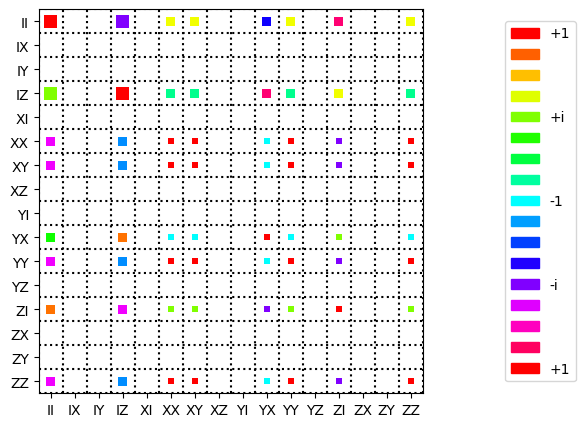

In [11]:
pauli_labels = ["I", "X", "Y", "Z"]
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
 'XI', 'XX', 'XY', 'XZ',
 'YI', 'YX', 'YY', 'YZ',
 'ZI', 'ZX', 'ZY', 'ZZ']

U_psi = Qobj(U_A)
# #Uncomment the following line to see that dme(pi/2) is in fact swap gate
# U_psi = gates.swap()

U_rho = spre(U_psi) * spost(U_psi.dag())
op_basis = [[qeye(2), sigmax(), sigmay(), sigmaz()]] * 2

chi = qpt(U_rho, op_basis)
plot_process_matrix(np.asarray(chi), pauli_labels_2q)